# 23CSE301 ML Capstone — EV Charging Station Opportunity Analysis
## Review 2: Classification Part B

### Problem Statement
This notebook classifies EV charging station locations into **Low, Medium, or High Profit Potential** using station and location attributes.

### Target Variable
- **Target (`y`):** `Profit_Potential`
- **Input features (`X`):** selected station and location characteristics.



## 0. Imports and Configuration

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, BaggingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from sklearn.base import clone

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "Profit_Potential"

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

## 1. Load and Understand the Dataset

In [2]:
df = pd.read_excel("EV_Charging_Station.xlsx")
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Shape: (65134, 23)
Rows: 65134
Columns: 23


,Station Name,City,State,ZIP,Status Code,EV Level1 EVSE Num,EV Level2 EVSE Num,EV DC Fast Count,EV Network,EV Connector Types,Latitude,Longitude,Owner Type Code,Open Date,Facility Type,EV Pricing,Restricted Access,EV Workplace Charging,Access Code,Nearest_Station_Distance_km,Competition_Level,Profit_Potential,Opportunity_Score
0,LADWP - Truesdale Center,Sun Valley,CA,91352,E,NaN,57.0,2.0,SHELL_RECHARGE,CHADEMO J1772 J1772COMBO,34.248319,-118.387971,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.738,Low,High,79.46
1,Los Angeles Convention Center,Los Angeles,CA,90015,E,NaN,7.0,NaN,Non-Networked,J1772,34.040539,-118.271387,P,34941.0,PARKING_GARAGE,Free; parking fee,0.0,0.0,public,0.287,Medium,Medium,66.09
2,LADWP - John Ferraro Building,Los Angeles,CA,90012,E,NaN,338.0,12.0,Non-Networked,CHADEMO J1772 J1772COMBO,34.059133,-118.248589,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.000,High,Low,2.35
3,LADWP - Haynes Power Plant,Long Beach,CA,90803,E,NaN,19.0,1.0,Non-Networked,CHADEMO J1772 J1772COMBO,33.759802,-118.096665,LG,43221.0,UTILITY,NaN,NaN,1.0,private,1.032,Low,High,83.53
4,LADWP - Harbor Generating Station,Wilmington,CA,90744,E,NaN,10.0,NaN,Non-Networked,J1772,33.770508,-118.265628,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.278,Medium,Medium,65.67


,Station Name,City,State,ZIP,Status Code,EV Level1 EVSE Num,EV Level2 EVSE Num,EV DC Fast Count,EV Network,EV Connector Types,Latitude,Longitude,Owner Type Code,Open Date,Facility Type,EV Pricing,Restricted Access,EV Workplace Charging,Access Code,Nearest_Station_Distance_km,Competition_Level,Profit_Potential,Opportunity_Score
0,LADWP - Truesdale Center,Sun Valley,CA,91352,E,NaN,57.0,2.0,SHELL_RECHARGE,CHADEMO J1772 J1772COMBO,34.248319,-118.387971,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.738,Low,High,79.46
1,Los Angeles Convention Center,Los Angeles,CA,90015,E,NaN,7.0,NaN,Non-Networked,J1772,34.040539,-118.271387,P,34941.0,PARKING_GARAGE,Free; parking fee,0.0,0.0,public,0.287,Medium,Medium,66.09
2,LADWP - John Ferraro Building,Los Angeles,CA,90012,E,NaN,338.0,12.0,Non-Networked,CHADEMO J1772 J1772COMBO,34.059133,-118.248589,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.000,High,Low,2.35
3,LADWP - Haynes Power Plant,Long Beach,CA,90803,E,NaN,19.0,1.0,Non-Networked,CHADEMO J1772 J1772COMBO,33.759802,-118.096665,LG,43221.0,UTILITY,NaN,NaN,1.0,private,1.032,Low,High,83.53
4,LADWP - Harbor Generating Station,Wilmington,CA,90744,E,NaN,10.0,NaN,Non-Networked,J1772,33.770508,-118.265628,LG,36448.0,UTILITY,NaN,NaN,1.0,private,0.278,Medium,Medium,65.67


### 1.1 Dataset audit

In [3]:
structure = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Missing Values": df.isna().sum().values,
    "Unique Values": df.nunique(dropna=True).values,
})
display(structure)

print("Duplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df[TARGET].value_counts(dropna=False).to_frame("Count"))

,Column,Data Type,Missing Values,Unique Values
0,Station Name,object,1,62509
1,City,object,5,6494
2,State,object,14,52
3,ZIP,object,1,11104
4,Status Code,object,0,1
5,EV Level1 EVSE Num,float64,64467,37
6,EV Level2 EVSE Num,float64,8457,73
7,EV DC Fast Count,float64,55770,43
8,EV Network,object,2,45
9,EV Connector Types,object,36,28


Duplicate rows: 13

Target distribution:


,Count
Profit_Potential,
Low,21713
High,21711
Medium,21710


### 1.2 Visualize the target distribution

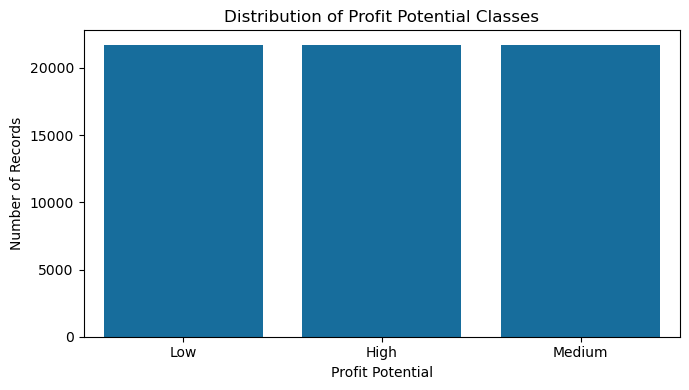

In [3]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x=TARGET, order=df[TARGET].value_counts().index, color=sns.color_palette("colorblind")[0])
ax.set_title("Distribution of Profit Potential Classes")
ax.set_xlabel("Profit Potential")
ax.set_ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Write your own observation about the class distribution here before submission.

## 2. Cleaning and Feature Engineering

In [4]:
data = df.copy()
before = len(data)
data = data.drop_duplicates().copy()
print("Duplicate rows removed:", before - len(data))
data = data.dropna(subset=[TARGET]).copy()
data[TARGET] = data[TARGET].astype(str)


if "Open Date" in data.columns:
    open_date = pd.to_datetime(data["Open Date"], unit="D", origin="1899-12-30", errors="coerce")
    data["Open Year"] = open_date.dt.year
    data["Station Age"] = 2024 - data["Open Year"]

if "EV Connector Types" in data.columns:
    data["Num Connector Types"] = (
        data["EV Connector Types"].fillna("").astype(str).str.strip()
        .apply(lambda value: 0 if not value else len(set(value.split())))
    )

if "EV Network" in data.columns:
    data["Is Networked"] = (
        data["EV Network"].fillna("Non-Networked").astype(str).str.lower()
        .ne("non-networked").astype(int)
    )

if "EV Pricing" in data.columns:
    data["Has Pricing"] = data["EV Pricing"].notna().astype(int)

if "EV Workplace Charging" in data.columns:
    data["Has Workplace Charging"] = (
        pd.to_numeric(data["EV Workplace Charging"], errors="coerce").fillna(0) > 0
    ).astype(int)

print("Shape after cleaning and feature engineering:", data.shape)

Duplicate rows removed: 13
Shape after cleaning and feature engineering: (65121, 29)


Shape after cleaning and feature engineering: (65121, 29)


## 3. Select Features and Avoid Target Leakage

In [5]:
MODEL_SAMPLE_SIZE = 8000
if MODEL_SAMPLE_SIZE is not None and len(data) > MODEL_SAMPLE_SIZE:
    _, data = train_test_split(
        data,
        test_size=MODEL_SAMPLE_SIZE,
        random_state=RANDOM_STATE,
        stratify=data[TARGET]
    )
    data = data.copy()
print("Rows used for modelling:", len(data))


feature_candidates = [
    "Latitude", "Longitude", "Open Year", "Station Age",
    "Num Connector Types", "Is Networked", "Has Pricing",
    "Has Workplace Charging", "EV Level1 EVSE Num", "EV Level2 EVSE Num",
    "EV DC Fast Count", "State", "EV Network", "Facility Type",
    "Owner Type Code", "Access Code", "Status Code", "Restricted Access"
]

leakage_columns = [
    "Opportunity_Score",
    "Nearest_Station_Distance_km",
    "Competition_Level",
    TARGET,
]
features = [c for c in feature_candidates if c in data.columns and c not in leakage_columns]

X = data[features].copy()
y = data[TARGET].copy()

print("Target variable:", TARGET)
print("Input feature count:", len(features))
print("Input features:", features)
print("Excluded leakage-related columns:", leakage_columns[:-1])

Rows used for modelling: 8000
Target variable: Profit_Potential
Input feature count: 18
Input features: ['Latitude', 'Longitude', 'Open Year', 'Station Age', 'Num Connector Types', 'Is Networked', 'Has Pricing', 'Has Workplace Charging', 'EV Level1 EVSE Num', 'EV Level2 EVSE Num', 'EV DC Fast Count', 'State', 'EV Network', 'Facility Type', 'Owner Type Code', 'Access Code', 'Status Code', 'Restricted Access']
Excluded leakage-related columns: ['Opportunity_Score', 'Nearest_Station_Distance_km', 'Competition_Level']


## 4. Train/Test Split and Preprocessing

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit imputation, encoding, and scaling on training data only.
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Training shape: (6400, 18)
Testing shape: (1600, 18)
Processed training shape: (6400, 168)
Processed testing shape: (1600, 168)


### Evaluation function

In [7]:
models = {}
predictions = {}
scores = {}
results = {}


def evaluate_model(name, model):
    """Calculate required metrics and save predictions/scores for later plots."""
    y_pred = model.predict(X_test_processed)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test_processed)
    else:
        y_score = model.decision_function(X_test_processed)

    class_labels = model.classes_
    if hasattr(model, "predict_proba"):
        auc = roc_auc_score(
            y_test,
            y_score,
            labels=class_labels,
            multi_class="ovr",
            average="weighted"
        )
    else:
        # For SVC decision scores, calculate one ROC-AUC per class and
        # average them using each class's support (One-vs-Rest).
        from sklearn.preprocessing import label_binarize
        y_test_binary = label_binarize(y_test, classes=class_labels)
        class_auc = []
        class_support = []
        for class_index, class_label in enumerate(class_labels):
            class_auc.append(roc_auc_score(y_test_binary[:, class_index], y_score[:, class_index]))
            class_support.append(int((y_test == class_label).sum()))
        auc = np.average(class_auc, weights=class_support)

    row = {
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (OvR)": auc,
    }
    predictions[name] = y_pred
    scores[name] = y_score
    results[name] = row

    print(name)
    display(pd.DataFrame([row]).set_index("Algorithm").round(4))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    print("Confusion matrix:")
    display(pd.DataFrame(
        confusion_matrix(y_test, y_pred, labels=class_labels),
        index=[f"Actual {c}" for c in class_labels],
        columns=[f"Predicted {c}" for c in class_labels]
    ))
    return row

## 5. Classification Part A — Reference Models from Review 1

These five models are included so the final Review 2 notebook can display one consolidated comparison table containing all ten required classification algorithms.

### 1. Logistic Regression

In [9]:
models["Logistic Regression"] = LogisticRegression(max_iter=300, random_state=RANDOM_STATE)
models["Logistic Regression"].fit(X_train_processed, y_train)
evaluate_model("Logistic Regression", models["Logistic Regression"])

Logistic Regression


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Logistic Regression,0.5919,0.5789,0.5919,0.5597,0.7574



Classification report:
              precision    recall  f1-score   support

        High       0.64      0.64      0.64       534
         Low       0.59      0.89      0.71       533
      Medium       0.51      0.25      0.33       533

    accuracy                           0.59      1600
   macro avg       0.58      0.59      0.56      1600
weighted avg       0.58      0.59      0.56      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,344,101,89
Actual Low,25,472,36
Actual Medium,169,233,131


{'Algorithm': 'Logistic Regression',
 'Accuracy': 0.591875,
 'Precision (weighted)': 0.5789484407438878,
 'Recall (weighted)': 0.591875,
 'F1-score (weighted)': 0.5596715851324058,
 'ROC-AUC (OvR)': 0.7573717131812115}

### 2. K-Nearest Neighbors

In [10]:
models["K-Nearest Neighbors"] = KNeighborsClassifier(n_neighbors=7, weights="distance")
models["K-Nearest Neighbors"].fit(X_train_processed, y_train)
evaluate_model("K-Nearest Neighbors", models["K-Nearest Neighbors"])

K-Nearest Neighbors


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
K-Nearest Neighbors,0.5538,0.5396,0.5538,0.5434,0.75



Classification report:
              precision    recall  f1-score   support

        High       0.56      0.60      0.58       534
         Low       0.64      0.74      0.68       533
      Medium       0.42      0.33      0.37       533

    accuracy                           0.55      1600
   macro avg       0.54      0.55      0.54      1600
weighted avg       0.54      0.55      0.54      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,319,68,147
Actual Low,47,392,94
Actual Medium,203,155,175


{'Algorithm': 'K-Nearest Neighbors',
 'Accuracy': 0.55375,
 'Precision (weighted)': 0.5395812120130346,
 'Recall (weighted)': 0.55375,
 'F1-score (weighted)': 0.5434080931208782,
 'ROC-AUC (OvR)': 0.7500384180189937}

### 3. Gaussian Naive Bayes

In [11]:
models["Gaussian Naive Bayes"] = GaussianNB()
models["Gaussian Naive Bayes"].fit(X_train_processed, y_train)
evaluate_model("Gaussian Naive Bayes", models["Gaussian Naive Bayes"])

Gaussian Naive Bayes


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Gaussian Naive Bayes,0.4388,0.5256,0.4388,0.3629,0.6625



Classification report:
              precision    recall  f1-score   support

        High       0.74      0.17      0.28       534
         Low       0.41      0.99      0.58       533
      Medium       0.43      0.15      0.23       533

    accuracy                           0.44      1600
   macro avg       0.53      0.44      0.36      1600
weighted avg       0.53      0.44      0.36      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,93,335,106
Actual Low,2,527,4
Actual Medium,31,420,82


{'Algorithm': 'Gaussian Naive Bayes',
 'Accuracy': 0.43875,
 'Precision (weighted)': 0.5255512612245561,
 'Recall (weighted)': 0.43875,
 'F1-score (weighted)': 0.36286309252398596,
 'ROC-AUC (OvR)': 0.662482552100276}

### 4. Decision Tree Classifier

In [12]:
models["Decision Tree Classifier"] = DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE)
models["Decision Tree Classifier"].fit(X_train_processed, y_train)
evaluate_model("Decision Tree Classifier", models["Decision Tree Classifier"])

Decision Tree Classifier


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Decision Tree Classifier,0.5781,0.5528,0.5781,0.5436,0.7305



Classification report:
              precision    recall  f1-score   support

        High       0.58      0.74      0.65       534
         Low       0.62      0.78      0.69       533
      Medium       0.46      0.21      0.29       533

    accuracy                           0.58      1600
   macro avg       0.55      0.58      0.54      1600
weighted avg       0.55      0.58      0.54      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,396,74,64
Actual Low,48,417,68
Actual Medium,240,181,112


{'Algorithm': 'Decision Tree Classifier',
 'Accuracy': 0.578125,
 'Precision (weighted)': 0.5528494800975287,
 'Recall (weighted)': 0.578125,
 'F1-score (weighted)': 0.5436169437890357,
 'ROC-AUC (OvR)': 0.7305210824346636}

### 5. Support Vector Machine (SVC)

A linear SVC can be slow on this dataset. To keep runtime manageable, it is trained on a stratified sample of up to 1,200 training rows and evaluated on the same untouched test set. This matches the runtime strategy noted in the Review 1 notebook.

In [13]:
SVC_MAX_TRAIN_ROWS = 1200
if len(y_train) > SVC_MAX_TRAIN_ROWS:
    X_svc_train, _, y_svc_train, _ = train_test_split(
        X_train_processed, y_train,
        train_size=SVC_MAX_TRAIN_ROWS,
        random_state=RANDOM_STATE,
        stratify=y_train
    )
else:
    X_svc_train, y_svc_train = X_train_processed, y_train

models["Support Vector Machine"] = SVC(
    kernel="linear", C=1.0, probability=False,
    decision_function_shape="ovr", random_state=RANDOM_STATE
)
models["Support Vector Machine"].fit(X_svc_train, y_svc_train)
evaluate_model("Support Vector Machine", models["Support Vector Machine"])

Support Vector Machine


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Support Vector Machine,0.5525,0.5327,0.5525,0.5201,0.7187



Classification report:
              precision    recall  f1-score   support

        High       0.59      0.53      0.56       534
         Low       0.57      0.89      0.70       533
      Medium       0.44      0.24      0.31       533

    accuracy                           0.55      1600
   macro avg       0.53      0.55      0.52      1600
weighted avg       0.53      0.55      0.52      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,281,110,143
Actual Low,37,477,19
Actual Medium,159,248,126


{'Algorithm': 'Support Vector Machine',
 'Accuracy': 0.5525,
 'Precision (weighted)': 0.5326539724207247,
 'Recall (weighted)': 0.5525,
 'F1-score (weighted)': 0.520087866001311,
 'ROC-AUC (OvR)': np.float64(0.7186546093929956)}

## 6. Classification Part B — Required Review 2 Models

The following are the five algorithms assessed in Review 2 Part B. All are evaluated on the same held-out test set.

### 6.1 Random Forest Classifier

In [14]:
# Use a shallow baseline first; tune the model later in Section 7.
models["Random Forest Classifier"] = RandomForestClassifier(
    n_estimators=30, max_depth=4, random_state=RANDOM_STATE, n_jobs=1
)
models["Random Forest Classifier"].fit(X_train_processed, y_train)
evaluate_model("Random Forest Classifier", models["Random Forest Classifier"])

Random Forest Classifier


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Random Forest Classifier,0.5812,0.6087,0.5812,0.498,0.752



Classification report:
              precision    recall  f1-score   support

        High       0.59      0.76      0.67       534
         Low       0.57      0.91      0.70       533
      Medium       0.67      0.07      0.13       533

    accuracy                           0.58      1600
   macro avg       0.61      0.58      0.50      1600
weighted avg       0.61      0.58      0.50      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,405,114,15
Actual Low,42,487,4
Actual Medium,235,260,38


{'Algorithm': 'Random Forest Classifier',
 'Accuracy': 0.58125,
 'Precision (weighted)': 0.608700600474794,
 'Recall (weighted)': 0.58125,
 'F1-score (weighted)': 0.49798539291664484,
 'ROC-AUC (OvR)': 0.7519710269143729}

### 6.2 AdaBoost Classifier

In [15]:
models["AdaBoost Classifier"] = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1, random_state=RANDOM_STATE),
    n_estimators=40,
    learning_rate=0.5,
    random_state=RANDOM_STATE
)
models["AdaBoost Classifier"].fit(X_train_processed, y_train)
evaluate_model("AdaBoost Classifier", models["AdaBoost Classifier"])

AdaBoost Classifier


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
AdaBoost Classifier,0.5419,0.3614,0.5419,0.4334,0.7241



Classification report:
              precision    recall  f1-score   support

        High       0.54      0.78      0.64       534
         Low       0.54      0.85      0.66       533
      Medium       0.00      0.00      0.00       533

    accuracy                           0.54      1600
   macro avg       0.36      0.54      0.43      1600
weighted avg       0.36      0.54      0.43      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,416,118,0
Actual Low,82,451,0
Actual Medium,266,267,0


{'Algorithm': 'AdaBoost Classifier',
 'Accuracy': 0.541875,
 'Precision (weighted)': 0.3614399197437311,
 'Recall (weighted)': 0.541875,
 'F1-score (weighted)': 0.4334168865175508,
 'ROC-AUC (OvR)': 0.7240539054546159}

### 6.3 Gradient Boosting Classifier

In [16]:
models["Gradient Boosting Classifier"] = GradientBoostingClassifier(
    n_estimators=40, learning_rate=0.1, max_depth=2, random_state=RANDOM_STATE
)
models["Gradient Boosting Classifier"].fit(X_train_processed, y_train)
evaluate_model("Gradient Boosting Classifier", models["Gradient Boosting Classifier"])

Gradient Boosting Classifier


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Gradient Boosting Classifier,0.6088,0.5912,0.6088,0.5715,0.7717



Classification report:
              precision    recall  f1-score   support

        High       0.62      0.70      0.66       534
         Low       0.62      0.90      0.73       533
      Medium       0.53      0.23      0.32       533

    accuracy                           0.61      1600
   macro avg       0.59      0.61      0.57      1600
weighted avg       0.59      0.61      0.57      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,373,80,81
Actual Low,26,478,29
Actual Medium,198,212,123


{'Algorithm': 'Gradient Boosting Classifier',
 'Accuracy': 0.60875,
 'Precision (weighted)': 0.5911766339640906,
 'Recall (weighted)': 0.60875,
 'F1-score (weighted)': 0.5715329343181288,
 'ROC-AUC (OvR)': 0.7717282119125531}

### 6.4 Bagging Classifier

In [17]:
models["Bagging Classifier"] = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=15,
    max_samples=0.8,
    n_jobs=1,
    random_state=RANDOM_STATE
)
models["Bagging Classifier"].fit(X_train_processed, y_train)
evaluate_model("Bagging Classifier", models["Bagging Classifier"])

Bagging Classifier


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Bagging Classifier,0.5844,0.5736,0.5844,0.5757,0.7634



Classification report:
              precision    recall  f1-score   support

        High       0.60      0.66      0.63       534
         Low       0.65      0.72      0.68       533
      Medium       0.47      0.37      0.42       533

    accuracy                           0.58      1600
   macro avg       0.57      0.58      0.58      1600
weighted avg       0.57      0.58      0.58      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,355,60,119
Actual Low,51,382,100
Actual Medium,185,150,198


{'Algorithm': 'Bagging Classifier',
 'Accuracy': 0.584375,
 'Precision (weighted)': 0.5736060075403117,
 'Recall (weighted)': 0.584375,
 'F1-score (weighted)': 0.5757227485380116,
 'ROC-AUC (OvR)': 0.7633905835960619}

### 6.5 MLP Classifier (Neural Network)

In [18]:
models["MLP Classifier"] = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation="relu",
    max_iter=20,
    early_stopping=False,
    random_state=RANDOM_STATE
)
models["MLP Classifier"].fit(X_train_processed, y_train)
evaluate_model("MLP Classifier", models["MLP Classifier"])

MLP Classifier


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
MLP Classifier,0.5825,0.5662,0.5825,0.5687,0.7672



Classification report:
              precision    recall  f1-score   support

        High       0.60      0.65      0.62       534
         Low       0.65      0.77      0.70       533
      Medium       0.46      0.33      0.38       533

    accuracy                           0.58      1600
   macro avg       0.57      0.58      0.57      1600
weighted avg       0.57      0.58      0.57      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,346,65,123
Actual Low,36,411,86
Actual Medium,197,161,175


{'Algorithm': 'MLP Classifier',
 'Accuracy': 0.5825,
 'Precision (weighted)': 0.5661940083169764,
 'Recall (weighted)': 0.5825,
 'F1-score (weighted)': 0.5686953517760266,
 'ROC-AUC (OvR)': 0.7671541279314098}

## 7. Random Forest Hyperparameter Tuning

GridSearchCV tunes the Random Forest on a stratified subset of the training data to limit runtime. The final comparison still evaluates the tuned model on the same held-out test set.

In [19]:
# Preserve the baseline metrics and predictions for a before/after comparison.
baseline_rf_row = results["Random Forest Classifier"].copy()
baseline_rf_pred = predictions["Random Forest Classifier"].copy()

TUNING_SAMPLE_SIZE = min(4000, len(y_train))
if len(y_train) > TUNING_SAMPLE_SIZE:
    X_tune, _, y_tune, _ = train_test_split(
        X_train_processed, y_train,
        train_size=TUNING_SAMPLE_SIZE,
        random_state=RANDOM_STATE,
        stratify=y_train
    )
else:
    X_tune, y_tune = X_train_processed, y_train

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    param_grid={
        "n_estimators": [30, 60],
        "max_depth": [6, None]
    },
    scoring="f1_weighted",
    cv=3,
    n_jobs=1,
    verbose=0
)
rf_grid.fit(X_tune, y_tune)

print("Best Random Forest parameters:")
print(rf_grid.best_params_)
print("Best cross-validation weighted F1:", round(rf_grid.best_score_, 4))

models["Random Forest Classifier"] = RandomForestClassifier(
    **rf_grid.best_params_, random_state=RANDOM_STATE, n_jobs=1
)
models["Random Forest Classifier"].fit(X_train_processed, y_train)
tuned_rf_row = evaluate_model("Random Forest Classifier", models["Random Forest Classifier"])

rf_tuning_comparison = pd.DataFrame([
    {"Version": "Baseline Random Forest", **{k: v for k, v in baseline_rf_row.items() if k != "Algorithm"}},
    {"Version": "Tuned Random Forest", **{k: v for k, v in tuned_rf_row.items() if k != "Algorithm"}},
]).set_index("Version")
display(rf_tuning_comparison.round(4))

Best Random Forest parameters:
{'max_depth': 6, 'n_estimators': 30}
Best cross-validation weighted F1: 0.5468
Random Forest Classifier


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Algorithm,,,,,
Random Forest Classifier,0.6019,0.5794,0.6019,0.5542,0.7635



Classification report:
              precision    recall  f1-score   support

        High       0.61      0.74      0.67       534
         Low       0.62      0.89      0.73       533
      Medium       0.51      0.18      0.27       533

    accuracy                           0.60      1600
   macro avg       0.58      0.60      0.55      1600
weighted avg       0.58      0.60      0.55      1600

Confusion matrix:


,Predicted High,Predicted Low,Predicted Medium
Actual High,394,76,64
Actual Low,32,473,28
Actual Medium,220,217,96


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
Version,,,,,
Baseline Random Forest,0.5812,0.6087,0.5812,0.4980,0.7520
Tuned Random Forest,0.6019,0.5794,0.6019,0.5542,0.7635


## 8. Consolidated Comparison Table — All 10 Algorithms

In [20]:
comparison_df = pd.DataFrame(results.values())
comparison_df = comparison_df.sort_values("F1-score (weighted)", ascending=False).reset_index(drop=True)
display(comparison_df.round(4))

best_algorithm = comparison_df.iloc[0]["Algorithm"]
print("Top model by weighted F1-score:", best_algorithm)
print("Use your results table to justify your final model choice in your own words.")

,Algorithm,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted),ROC-AUC (OvR)
0,Bagging Classifier,0.5844,0.5736,0.5844,0.5757,0.7634
1,Gradient Boosting Classifier,0.6088,0.5912,0.6088,0.5715,0.7717
2,MLP Classifier,0.5825,0.5662,0.5825,0.5687,0.7672
3,Logistic Regression,0.5919,0.5789,0.5919,0.5597,0.7574
4,Random Forest Classifier,0.6019,0.5794,0.6019,0.5542,0.7635
5,Decision Tree Classifier,0.5781,0.5528,0.5781,0.5436,0.7305
6,K-Nearest Neighbors,0.5538,0.5396,0.5538,0.5434,0.7500
7,Support Vector Machine,0.5525,0.5327,0.5525,0.5201,0.7187
8,AdaBoost Classifier,0.5419,0.3614,0.5419,0.4334,0.7241
9,Gaussian Naive Bayes,0.4388,0.5256,0.4388,0.3629,0.6625


Top model by weighted F1-score: Bagging Classifier
Use your results table to justify your final model choice in your own words.


## 9. Cross-Validation for the Two Best Models

To keep computation manageable, three-fold cross-validation uses a stratified subset of the training data. The test set is not used during cross-validation.

In [21]:
cv_sample_size = min(3000, len(y_train))
if len(y_train) > cv_sample_size:
    X_cv, _, y_cv, _ = train_test_split(
        X_train, y_train,
        train_size=cv_sample_size,
        random_state=RANDOM_STATE,
        stratify=y_train
    )
else:
    X_cv, y_cv = X_train, y_train

cv_rows = []
for model_name in comparison_df.head(2)["Algorithm"]:
    # Refit preprocessing inside each fold to avoid validation-fold leakage.
    cv_pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(models[model_name]))
    ])
    cv_scores = cross_val_score(
        cv_pipeline, X_cv, y_cv,
        cv=3,
        scoring="f1_weighted",
        n_jobs=1
    )
    cv_rows.append({
        "Algorithm": model_name,
        "3-Fold CV Weighted F1 Mean": cv_scores.mean(),
        "3-Fold CV Weighted F1 Std": cv_scores.std()
    })

display(pd.DataFrame(cv_rows).round(4))


,Algorithm,3-Fold CV Weighted F1 Mean,3-Fold CV Weighted F1 Std
0,Bagging Classifier,0.5488,0.0078
1,Gradient Boosting Classifier,0.5483,0.0081


## 10. Confusion Matrices for All 10 Algorithms

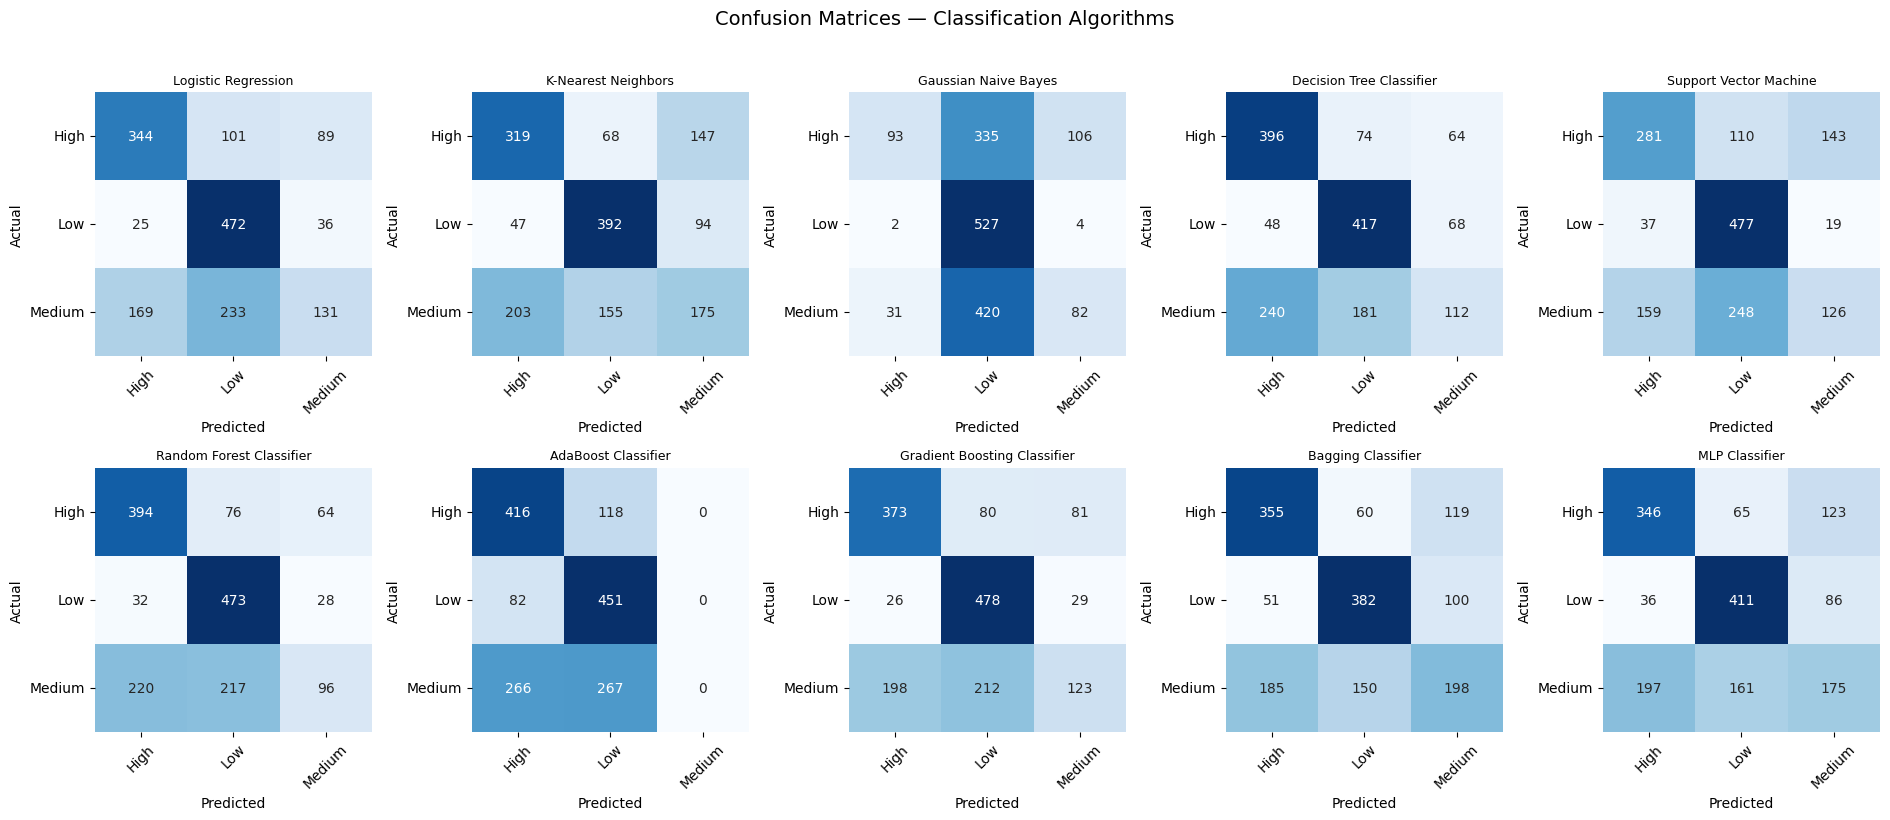

In [22]:
algorithm_names = list(models.keys())
fig, axes = plt.subplots(2, 5, figsize=(19, 8))
axes = axes.ravel()

for ax, name in zip(axes, algorithm_names):
    cm = confusion_matrix(y_test, predictions[name], labels=models[name].classes_)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=models[name].classes_,
        yticklabels=models[name].classes_,
        ax=ax
    )
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle("Confusion Matrices — Classification Algorithms", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

## 11. Comparison Visualizations

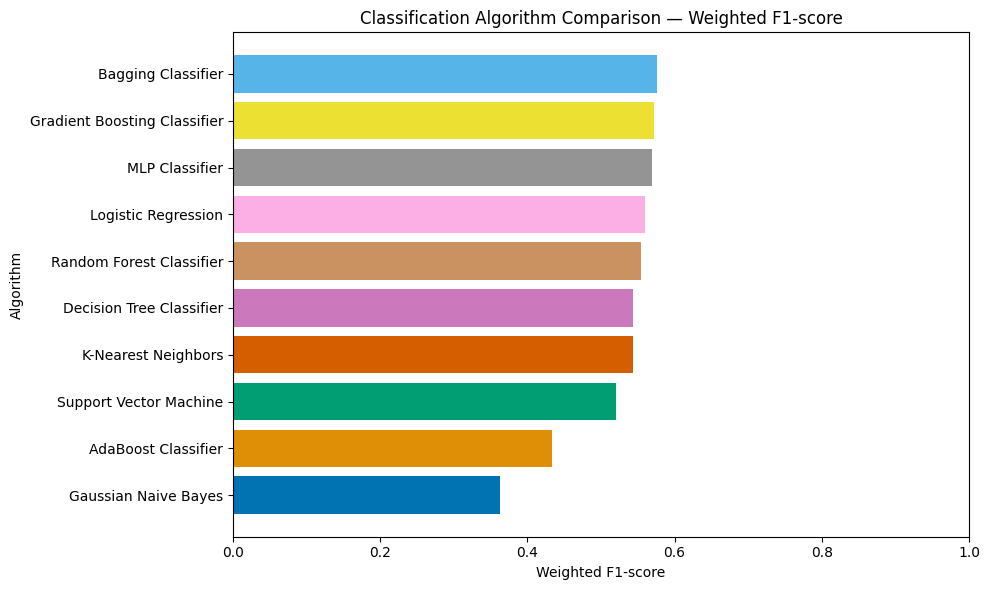

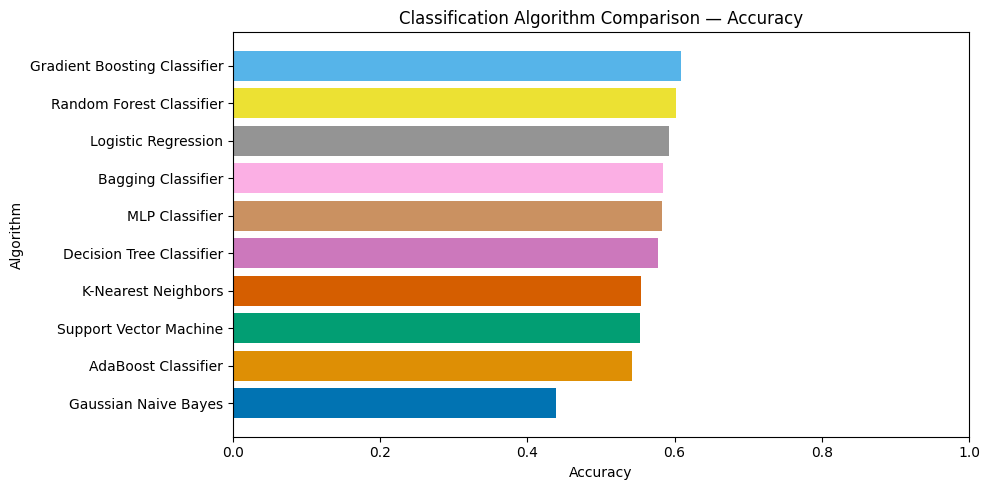

In [23]:
plot_df = comparison_df.sort_values("F1-score (weighted)", ascending=True)
plt.figure(figsize=(10, 6))
plt.barh(plot_df["Algorithm"], plot_df["F1-score (weighted)"], color=sns.color_palette("colorblind", n_colors=len(plot_df)))
plt.xlabel("Weighted F1-score")
plt.ylabel("Algorithm")
plt.title("Classification Algorithm Comparison — Weighted F1-score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plot_df = comparison_df.sort_values("Accuracy", ascending=True)
plt.barh(plot_df["Algorithm"], plot_df["Accuracy"], color=sns.color_palette("colorblind", n_colors=len(plot_df)))
plt.xlabel("Accuracy")
plt.ylabel("Algorithm")
plt.title("Classification Algorithm Comparison — Accuracy")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

## 12. Random Forest Feature Importance

,Feature,Importance
73,categorical__EV Network_ChargePoint Network,0.194826
2,numeric__Open Year,0.082401
6,numeric__Has Pricing,0.079797
3,numeric__Station Age,0.077938
1,numeric__Longitude,0.071751
9,numeric__EV Level2 EVSE Num,0.051552
68,categorical__EV Network_Blink Network,0.036939
16,categorical__State_CA,0.034358
123,categorical__Facility Type_HOTEL,0.033277
10,numeric__EV DC Fast Count,0.032959


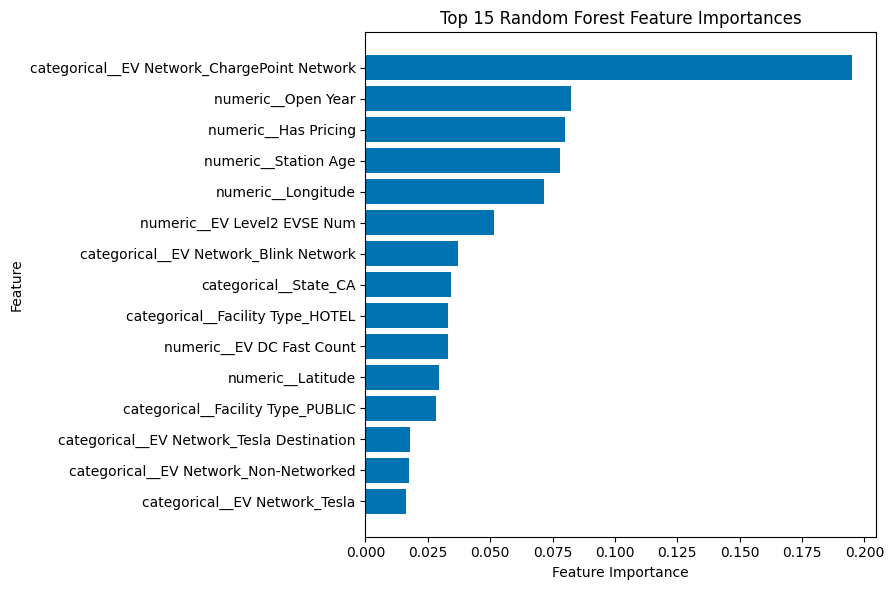

In [24]:
rf_final = models["Random Forest Classifier"]
feature_names = preprocessor.get_feature_names_out()
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_final.feature_importances_
}).sort_values("Importance", ascending=False).head(15)

display(importance_df)
plt.figure(figsize=(9, 6))
plt.barh(importance_df["Feature"].iloc[::-1], importance_df["Importance"].iloc[::-1], color=sns.color_palette("colorblind")[0])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()